# Question 1 — Iris Flower Classification using an MLP built from scratch

**Task.** Classify iris flowers into **Setosa, Versicolor and Virginica** from 4 measurements (sepal length/width, petal length/width).

**Constraint.** The neural network is implemented **from scratch with NumPy** (`mlp_scratch.py`): no
predefined MLP from sklearn / PyTorch / Keras. sklearn is only used to load the dataset, split it, scale it
and compute evaluation metrics (`helpers.py`).

| Item | Setting |
|---|---|
| Architectures (PDF) | 4–6–3 &nbsp;·&nbsp; 4–10–3 &nbsp;·&nbsp; 4–20–3 |
| Hidden activation | ReLU |
| Output | **Softmax** output layer (3 neurons) + **categorical cross-entropy** loss |
| Weight init | He-normal for hidden layers, Xavier-normal for output layer, biases = 0, seed 42 |
| Optimiser | Full-batch gradient descent, learning rate = 0.1, 1000 epochs |
| Splits | 70:30 and 80:20, **stratified**, `random_state=42` |
| Preprocessing | z-score standardisation fitted on the training set only |
| Extension | Same scratch code with **2–5 hidden layers** (section 9) |

**Contents**
1. Dataset · 2. Input preprocessing · 3. Step-by-step walk-through of one training iteration ·
4. Training the six experiments · 5. Performance metrics table · 6. Confusion matrices ·
7. Training loss curves · 8. Initial vs. updated weights · 9. Extension: 2–5 hidden layers · 10. Discussion

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from mlp_scratch import (MLP, relu, relu_derivative, softmax, sigmoid,
                         categorical_cross_entropy, binary_cross_entropy, one_hot, gradient_check)
import helpers as H

H.set_style()
np.set_printoptions(precision=4, suppress=True, linewidth=140)
pd.set_option("display.precision", 4)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
OUT_DIR = "results/q1"
os.makedirs(OUT_DIR, exist_ok=True)

## 1. Dataset

In [2]:
X, y, feature_names, class_names = H.load_data("iris")
df = pd.DataFrame(X, columns=feature_names)
df["class"] = [class_names[i] for i in y]
print("Samples:", X.shape[0], "| Features:", X.shape[1], "| Classes:", class_names)
display(df["class"].value_counts().rename("count").to_frame())
display(df.head())

Samples: 150 | Features: 4 | Classes: ['setosa', 'versicolor', 'virginica']


,count
class,
setosa,50
versicolor,50
virginica,50


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),class
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


,count,mean,std,min,25%,50%,75%,max
sepal length (cm),150.0,5.843,0.828,4.3,5.1,5.80,6.4,7.9
sepal width (cm),150.0,3.057,0.436,2.0,2.8,3.00,3.3,4.4
petal length (cm),150.0,3.758,1.765,1.0,1.6,4.35,5.1,6.9
petal width (cm),150.0,1.199,0.762,0.1,0.3,1.30,1.8,2.5


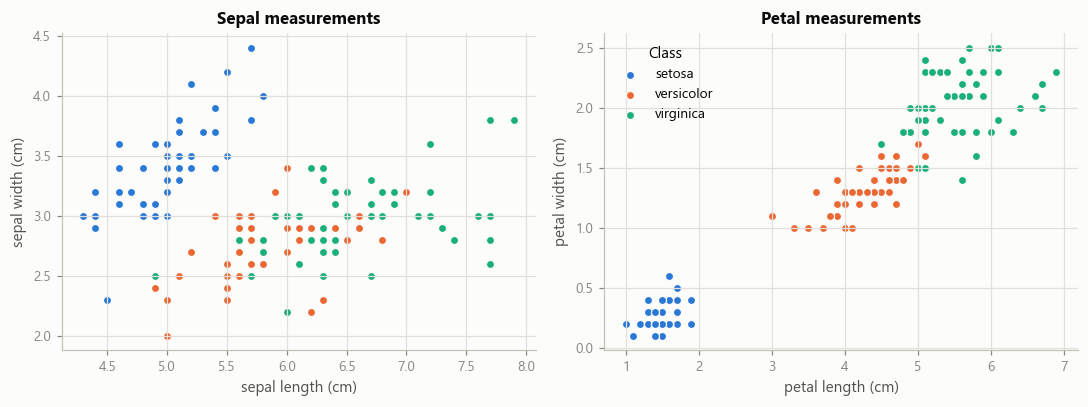

In [3]:
display(df.describe().T.round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, (a, b) in zip(axes, [(0, 1), (2, 3)]):
    for k, name in enumerate(class_names):
        m = y == k
        ax.scatter(X[m, a], X[m, b], s=28, color=H.SERIES[k], label=name, edgecolor=H.SURFACE, linewidth=0.8)
    ax.set_xlabel(feature_names[a]); ax.set_ylabel(feature_names[b])
axes[0].set_title("Sepal measurements"); axes[1].set_title("Petal measurements")
axes[1].legend(title="Class")
fig.tight_layout(); fig.savefig(f"{OUT_DIR}/dataset_scatter.png", dpi=150, bbox_inches="tight"); plt.show()

Setosa is linearly separable from the other two classes (especially on the petal features);
Versicolor and Virginica overlap slightly, so we expect any classification errors to be between those two.

## 2. Input preprocessing — train/test split and standardisation

For each split ratio we (1) split stratified so every class keeps its proportion and (2) standardise every
feature to zero mean / unit variance: $x' = (x - \mu_{train}) / \sigma_{train}$. The mean and standard
deviation are computed on the **training set only** and then applied to the test set, so the test data
stays truly unseen.

In [4]:
SPLITS = [0.30, 0.20]          # test fraction -> 70:30 and 80:20
rows = []
for ts in SPLITS:
    X_tr, X_te, y_tr, y_te, scaler = H.split_and_scale(X, y, ts)
    rows.append({"Split": H.split_name(ts), "Train samples": len(y_tr), "Test samples": len(y_te),
                 **{f"train {c}": int((y_tr == k).sum()) for k, c in enumerate(class_names)},
                 **{f"test {c}": int((y_te == k).sum()) for k, c in enumerate(class_names)},
                 "train mean after scaling": round(float(X_tr.mean()), 6),
                 "train std after scaling": round(float(X_tr.std()), 6)})
display(pd.DataFrame(rows).set_index("Split").T)

Split,70:30,80:20
Train samples,105.0,120.0
Test samples,45.0,30.0
train setosa,35.0,40.0
train versicolor,35.0,40.0
train virginica,35.0,40.0
test setosa,15.0,10.0
test versicolor,15.0,10.0
test virginica,15.0,10.0
train mean after scaling,0.0,-0.0
train std after scaling,1.0,1.0


## 3. Step-by-step walk-through of one training iteration (4–6–3, 70:30 split)

This section opens up the `MLP` class and performs every step by hand with NumPy, then checks that the
class does exactly the same thing. The steps demonstrated are those required by the assignment:
**input feeding → weight & bias initialisation → forward propagation (ReLU) → softmax output →
categorical cross-entropy loss → backpropagation → gradient calculation → gradient-descent update.**

### 3.1 Input feeding
The whole (scaled) training set is fed as one matrix $X$ of shape (samples × features); each row is one
sample. Below are the first 5 rows.

In [5]:
X_tr, X_te, y_tr, y_te, _ = H.split_and_scale(X, y, 0.30)
print("X_train shape:", X_tr.shape, "  y_train shape:", y_tr.shape)

display(pd.DataFrame(X_tr[:5], columns=feature_names).round(4).assign(label=[class_names[i] for i in y_tr[:5]]))

X_train shape: (105, 4)   y_train shape: (105,)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),label
0,-0.9005,-1.2202,-0.4420,-0.1366,versicolor
1,0.3804,-1.8796,0.4028,0.3803,versicolor
2,-0.9005,1.6368,-1.2868,-1.1704,setosa
3,1.0790,0.3181,1.1913,1.4141,virginica
4,-0.2018,-0.5609,0.1775,0.1218,versicolor


### 3.2 Weight and bias initialisation
For layer $l$ with $n_{in}$ inputs and $n_{out}$ outputs, $W^{[l]}$ has shape $(n_{in}, n_{out})$ and
$b^{[l]}$ has shape $(1, n_{out})$.

* Hidden layers feed into ReLU, so we use **He initialisation** $W \sim \mathcal N(0,\, 2/n_{in})$, which keeps
  the variance of activations roughly constant from layer to layer.
* The output layer uses **Xavier initialisation** $W \sim \mathcal N(0,\, 1/n_{in})$.
* Biases start at **0** (the random weights already break the symmetry between neurons).

In [6]:
model = MLP([4, 6, 3], output="softmax", seed=42)
print(model, "| trainable parameters:", model.n_params())
for l in range(model.n_layers):
    print(f"\nW{l+1} shape {model.W[l].shape}   b{l+1} shape {model.b[l].shape}")

    print(f"W{l+1} =\n{model.W[l]}\nb{l+1} = {model.b[l]}")

MLP(4-6-3, output=softmax) | trainable parameters: 51

W1 shape (4, 6)   b1 shape (1, 6)
W1 =
[[ 0.2155 -0.7354  0.5306  0.6651 -1.3796 -0.9208]
 [ 0.0904 -0.2236 -0.0119 -0.6032  0.6218  0.55  ]
 [ 0.0467  0.7971  0.3306 -0.6076  0.2607 -0.678 ]
 [ 0.6212 -0.0353 -0.1307 -0.4815  0.8645 -0.1093]]
b1 = [[0. 0. 0. 0. 0. 0.]]

W2 shape (6, 3)   b2 shape (1, 3)
W2 =
[[-0.1749 -0.1438  0.2173]
 [ 0.1492  0.1685  0.1759]
 [ 0.8743 -0.1659 -0.2091]
 [-0.3322  0.2515  0.4609]
 [-0.0465 -0.343  -0.3366]
 [ 0.2656  0.3034  0.2217]]
b2 = [[0. 0. 0.]]


### 3.3 Forward propagation
$$Z^{[1]} = X W^{[1]} + b^{[1]}, \qquad A^{[1]} = \mathrm{ReLU}(Z^{[1]}) = \max(0, Z^{[1]})$$
$$Z^{[2]} = A^{[1]} W^{[2]} + b^{[2]}, \qquad \hat Y = \mathrm{softmax}(Z^{[2]}),\quad \hat y_{ik} = \frac{e^{z_{ik}}}{\sum_j e^{z_{ij}}}$$
Each row of $\hat Y$ is a probability distribution over the three classes.

In [7]:
W1, b1, W2, b2 = model.W[0], model.b[0], model.W[1], model.b[1]
Z1 = X_tr @ W1 + b1
A1 = relu(Z1)
Z2 = A1 @ W2 + b2
P  = softmax(Z2)

print("Z1 (first 3 samples):\n", Z1[:3])
print("A1 = ReLU(Z1) (first 3 samples):\n", A1[:3])
print("Z2 (first 3 samples):\n", Z2[:3])
print("softmax probabilities P (first 3 samples):\n", P[:3])
print("rows of P sum to 1:", np.allclose(P.sum(axis=1), 1))
print("same as model.forward():", np.allclose(P, model.forward(X_tr)[0]))

Z1 (first 3 samples):
 [[-0.4098  0.5876 -0.5916  0.4715  0.2501  0.4726]
 [ 0.1671  0.4482  0.3076  0.9588 -1.2597 -1.6986]
 [-0.8332 -0.6882 -0.7697 -0.2407  0.9127  2.7297]]
A1 = ReLU(Z1) (first 3 samples):
 [[0.     0.5876 0.     0.4715 0.2501 0.4726]
 [0.1671 0.4482 0.3076 0.9588 0.     0.    ]
 [0.     0.     0.     0.     0.9127 2.7297]]
Z2 (first 3 samples):
 [[ 0.0449  0.2752  0.3413]
 [-0.0119  0.2416  0.4927]
 [ 0.6826  0.5152  0.2981]]
softmax probabilities P (first 3 samples):
 [[0.2775 0.3493 0.3732]
 [0.2535 0.3266 0.4199]
 [0.3958 0.3348 0.2694]]
rows of P sum to 1: True
same as model.forward(): True


### 3.4 Categorical cross-entropy loss
Labels are one-hot encoded ($y_{ik}=1$ for the true class). For $m$ samples
$$L = -\frac{1}{m}\sum_{i=1}^{m}\sum_{k=1}^{3} y_{ik}\log \hat y_{ik}$$
With random initial weights the network is essentially guessing, so the first loss is in the region of
$\ln 3 \approx 1.0986$ (the loss of predicting 1/3 for every class). It can be somewhat higher when the
random weights happen to make confident wrong predictions.

In [8]:
Y_tr = one_hot(y_tr, 3)
print("one-hot labels (first 3):\n", Y_tr[:3])
loss0 = categorical_cross_entropy(Y_tr, P)
print(f"initial loss = {loss0:.4f}   (ln 3 = {np.log(3):.4f})")

one-hot labels (first 3):
 [[0. 1. 0.]
 [0. 1. 0.]
 [1. 0. 0.]]
initial loss = 1.1687   (ln 3 = 1.0986)


### 3.5 Backpropagation and gradient calculation
Applying the chain rule from the loss back to every parameter. For softmax + categorical cross-entropy the derivative of the loss with respect to the output pre-activation simplifies to

$$dZ^{[2]} = \frac{\partial L}{\partial Z^{[2]}} = \frac{1}{m}(\hat Y - Y)$$

and then

$$dW^{[2]} = A^{[1]\top} dZ^{[2]}, \qquad db^{[2]} = \textstyle\sum_i dZ^{[2]}_i$$
$$dA^{[1]} = dZ^{[2]} W^{[2]\top}, \qquad dZ^{[1]} = dA^{[1]} \odot \mathrm{ReLU}'(Z^{[1]}), \quad \mathrm{ReLU}'(z)=\begin{cases}1 & z>0\\0 & z\le 0\end{cases}$$
$$dW^{[1]} = X^{\top} dZ^{[1]}, \qquad db^{[1]} = \textstyle\sum_i dZ^{[1]}_i$$

Each gradient has exactly the same shape as the parameter it updates.

In [9]:
m = X_tr.shape[0]
dZ2 = (P - Y_tr) / m
dW2 = A1.T @ dZ2
db2 = dZ2.sum(axis=0, keepdims=True)
dA1 = dZ2 @ W2.T
dZ1 = dA1 * relu_derivative(Z1)
dW1 = X_tr.T @ dZ1
db1 = dZ1.sum(axis=0, keepdims=True)

for name, g in [("dW1", dW1), ("db1", db1), ("dW2", dW2), ("db2", db2)]:
    print(f"{name} shape {g.shape}")
print("\ndW2 =\n", dW2)
print("db2 =", db2)

# the class's backward() must give identical gradients
_, cache = model.forward(X_tr)
dW_cls, db_cls = model.backward(Y_tr, cache)
print("\nmanual gradients == model.backward():",
      all(np.allclose(a, b) for a, b in zip([dW1, dW2, db1, db2], dW_cls + db_cls)))

dW1 shape (4, 6)
db1 shape (1, 6)
dW2 shape (6, 3)
db2 shape (1, 3)

dW2 =
 [[ 0.1747  0.0301 -0.2048]
 [ 0.0588 -0.0537 -0.0051]
 [ 0.1521 -0.0046 -0.1475]
 [-0.0332 -0.0339  0.0671]
 [-0.0548  0.0601 -0.0053]
 [-0.5321  0.2794  0.2527]]
db2 = [[ 0.0441 -0.035  -0.0091]]

manual gradients == model.backward(): True


**Gradient check.** To prove the backprop equations are implemented correctly, every analytical gradient
is compared with a numerical estimate $\frac{L(\theta+\varepsilon)-L(\theta-\varepsilon)}{2\varepsilon}$
(on a small batch). A relative error below $10^{-7}$ means the two agree.

In [10]:
check = gradient_check(MLP([4, 6, 3], output="softmax", seed=0), X_tr[:20], y_tr[:20])
display(pd.DataFrame(check, columns=["parameter", "shape", "relative error"]))

,parameter,shape,relative error
0,W1,"(4, 6)",4.2340e-11
1,b1,"(1, 6)",5.0198e-11
2,W2,"(6, 3)",2.1367e-11
3,b2,"(1, 3)",7.8676e-11


### 3.6 Weight and bias update (gradient descent)
$$W^{[l]} \leftarrow W^{[l]} - \eta\, dW^{[l]}, \qquad b^{[l]} \leftarrow b^{[l]} - \eta\, db^{[l]}$$
Below: one update step, after which the loss must decrease. Training (section 4) simply repeats
*forward → loss → backward → update* for every epoch.

In [11]:
lr = 0.1
W2_before = model.W[1].copy()
model.update(dW_cls, db_cls, lr)
loss1 = model.compute_loss(Y_tr, model.forward(X_tr)[0])
print(f"loss before update: {loss0:.6f}")
print(f"loss after  update: {loss1:.6f}   (decreased: {loss1 < loss0})")
print("\nW2 change after one step (= -lr * dW2):\n", model.W[1] - W2_before)

loss before update: 1.168668
loss after  update: 1.080198   (decreased: True)

W2 change after one step (= -lr * dW2):
 [[-0.0175 -0.003   0.0205]
 [-0.0059  0.0054  0.0005]
 [-0.0152  0.0005  0.0147]
 [ 0.0033  0.0034 -0.0067]
 [ 0.0055 -0.006   0.0005]
 [ 0.0532 -0.0279 -0.0253]]


## 4. Training the six experiments

3 architectures × 2 split ratios. Every model starts from the same seed (42) and is trained with
full-batch gradient descent, learning rate **0.1**, **1000 epochs**. Test loss is also recorded every
epoch (it is *not* used for training, only for the plots).

In [12]:
ARCHS  = [[4, 6, 3], [4, 10, 3], [4, 20, 3]]
LR, EPOCHS = 0.1, 1000

results = []
for ts in SPLITS:
    for arch in ARCHS:
        r = H.run_experiment(X, y, arch, "softmax", ts, lr=LR, epochs=EPOCHS)
        results.append(r)
        h = r["model"].history["train_loss"]
        print(f"{r['arch']:>8} | {r['split']} | loss {h[0]:.4f} -> {h[-1]:.4f} | "
              f"train acc {r['train']['accuracy']:.4f} | test acc {r['test']['accuracy']:.4f}")

   4-6-3 | 70:30 | loss 1.1687 -> 0.0365 | train acc 1.0000 | test acc 0.9111


  4-10-3 | 70:30 | loss 1.4565 -> 0.0374 | train acc 0.9905 | test acc 0.9111


  4-20-3 | 70:30 | loss 1.0446 -> 0.0350 | train acc 1.0000 | test acc 0.9111


   4-6-3 | 80:20 | loss 1.1714 -> 0.0508 | train acc 0.9750 | test acc 0.9667


  4-10-3 | 80:20 | loss 1.4378 -> 0.0483 | train acc 0.9833 | test acc 0.9333


  4-20-3 | 80:20 | loss 1.0419 -> 0.0459 | train acc 0.9833 | test acc 0.9667


## 5. Performance metrics table (test set)

Precision, recall and F1 are **macro-averaged** over the three classes (per-class values are printed in section 5).

In [13]:
table = H.metrics_table(results)
table.to_csv(f"{OUT_DIR}/metrics_table.csv")
display(H.format_table(table))

,Architecture,Split,Train / Test,Params,Final train loss,Train acc,Test acc,Precision,Recall,F1-score
Exp,,,,,,,,,,
1,4-6-3,70:30,105 / 45,51,0.0365,1.0000,0.9111,0.9155,0.9111,0.9107
2,4-10-3,70:30,105 / 45,83,0.0374,0.9905,0.9111,0.9155,0.9111,0.9107
3,4-20-3,70:30,105 / 45,163,0.0350,1.0000,0.9111,0.9155,0.9111,0.9107
4,4-6-3,80:20,120 / 30,51,0.0508,0.9750,0.9667,0.9697,0.9667,0.9666
5,4-10-3,80:20,120 / 30,83,0.0483,0.9833,0.9333,0.9333,0.9333,0.9333
6,4-20-3,80:20,120 / 30,163,0.0459,0.9833,0.9667,0.9697,0.9667,0.9666


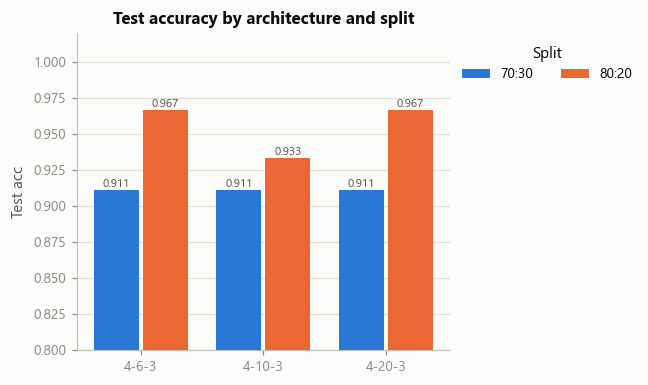

In [14]:
H.plot_metric_bars(table, "Test acc", "Test accuracy by architecture and split",
                   save=f"{OUT_DIR}/test_accuracy_bars.png", ylim=(0.8, 1.02)); plt.show()

**Per-class report for every experiment** (test set):

In [15]:
from sklearn.metrics import classification_report
for i, r in enumerate(results, 1):
    print(f"=== Exp {i}: {r['arch']}  ({r['split']}) ===")
    print(classification_report(r["y_test"], r["y_pred_test"], target_names=class_names, digits=4))

=== Exp 1: 4-6-3  (70:30) ===
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        15
  versicolor     0.8235    0.9333    0.8750        15
   virginica     0.9231    0.8000    0.8571        15

    accuracy                         0.9111        45
   macro avg     0.9155    0.9111    0.9107        45
weighted avg     0.9155    0.9111    0.9107        45

=== Exp 2: 4-10-3  (70:30) ===
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        15
  versicolor     0.8235    0.9333    0.8750        15
   virginica     0.9231    0.8000    0.8571        15

    accuracy                         0.9111        45
   macro avg     0.9155    0.9111    0.9107        45
weighted avg     0.9155    0.9111    0.9107        45

=== Exp 3: 4-20-3  (70:30) ===
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        15
  versicolor     0.8235    0.9333    

## 6. Confusion matrices (test set)
Rows = actual class, columns = predicted class; the diagonal holds the correct predictions.

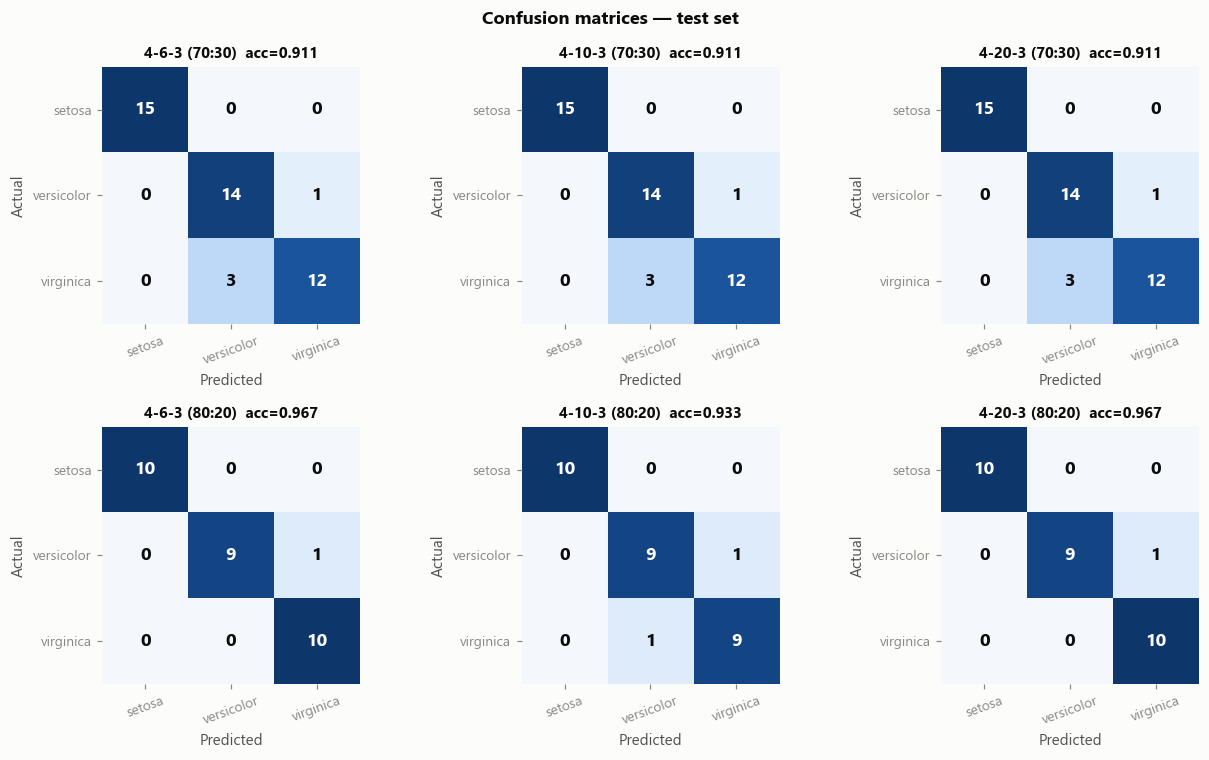

Exp 1 4-6-3 (70:30):


,pred setosa,pred versicolor,pred virginica
actual setosa,15,0,0
actual versicolor,0,14,1
actual virginica,0,3,12


Exp 2 4-10-3 (70:30):


,pred setosa,pred versicolor,pred virginica
actual setosa,15,0,0
actual versicolor,0,14,1
actual virginica,0,3,12


Exp 3 4-20-3 (70:30):


,pred setosa,pred versicolor,pred virginica
actual setosa,15,0,0
actual versicolor,0,14,1
actual virginica,0,3,12


... (2 outputs left out)

Exp 5 4-10-3 (80:20):


,pred setosa,pred versicolor,pred virginica
actual setosa,10,0,0
actual versicolor,0,9,1
actual virginica,0,1,9


Exp 6 4-20-3 (80:20):


,pred setosa,pred versicolor,pred virginica
actual setosa,10,0,0
actual versicolor,0,9,1
actual virginica,0,0,10


In [16]:
H.plot_confusion_matrices(results, class_names, "Confusion matrices — test set",
                          save=f"{OUT_DIR}/confusion_matrices.png"); plt.show()
for i, r in enumerate(results, 1):
    print(f"Exp {i} {r['arch']} ({r['split']}):")
    display(pd.DataFrame(r["test"]["cm"], index=[f"actual {c}" for c in class_names],
                         columns=[f"pred {c}" for c in class_names]))

## 7. Training loss curves
Log scale on the y-axis so both the fast initial drop and the slow later convergence are visible.

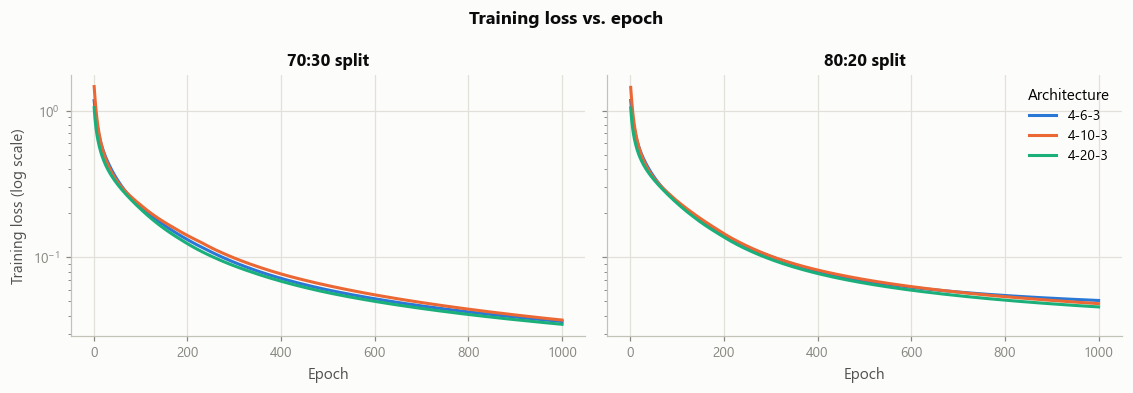

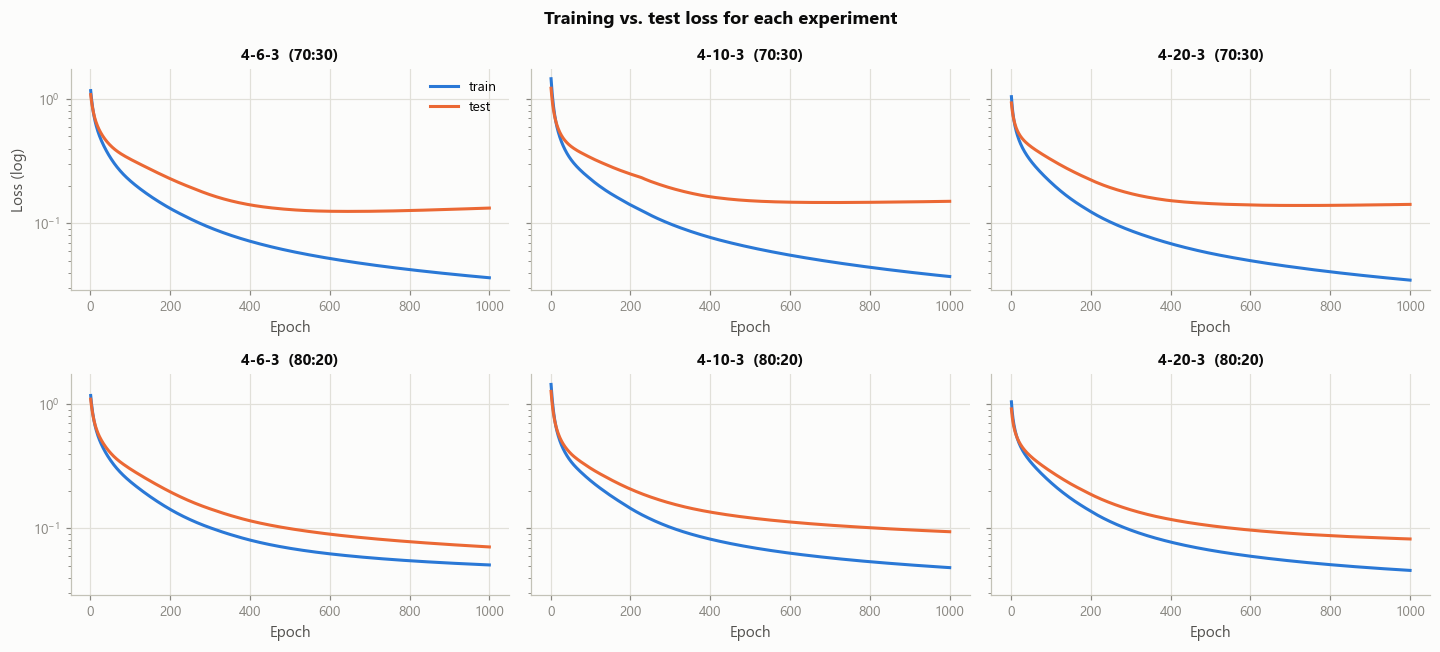

In [17]:
H.plot_loss_by_split(results, "Training loss vs. epoch", save=f"{OUT_DIR}/loss_curves.png"); plt.show()
H.plot_train_test_loss(results, "Training vs. test loss for each experiment",
                       save=f"{OUT_DIR}/train_vs_test_loss.png"); plt.show()

## 8. Initial vs. updated weight matrices

To demonstrate learning, the weights are stored right after initialisation (`model.W_init`) and compared
with the weights after training. First the full matrices for each experiment, then heatmaps
(blue = positive, red = negative, grey ≈ 0) and a summary of how much each layer changed.

In [18]:
for i, r in enumerate(results, 1):
    m = r["model"]
    display(Markdown(f"#### Exp {i}: {r['arch']} ({r['split']})"))
    for l in range(m.n_layers):
        init_df, final_df = H.weights_as_frames(m, l, in_labels=feature_names if l == 0 else None)
        print(f"W{l+1} — initial {m.W[l].shape}"); display(init_df)
        print(f"W{l+1} — after training"); display(final_df)
        print(f"b{l+1} — initial: {m.b_init[l].round(3)}\nb{l+1} — after training: {m.b[l].round(3)}\n")

#### Exp 1: 4-6-3 (70:30)

W1 — initial (4, 6)


,h1,h2,h3,h4,h5,h6
sepal length (cm),0.215,-0.735,0.531,0.665,-1.380,-0.921
sepal width (cm),0.090,-0.224,-0.012,-0.603,0.622,0.550
petal length (cm),0.047,0.797,0.331,-0.608,0.261,-0.678
petal width (cm),0.621,-0.035,-0.131,-0.481,0.864,-0.109


W1 — after training


,h1,h2,h3,h4,h5,h6
sepal length (cm),0.538,-0.832,0.267,1.054,-1.553,-1.371
sepal width (cm),-0.788,-0.294,-0.002,-0.685,0.767,0.656
petal length (cm),1.353,0.845,0.134,-0.289,-0.056,-1.411
petal width (cm),2.237,-0.032,-0.301,-0.365,0.550,-0.838


b1 — initial: [[0. 0. 0. 0. 0. 0.]]
b1 — after training: [[-1.161  0.469 -0.246  1.477  0.013  0.122]]

W2 — initial (6, 3)


... (50 outputs left out)

,out1,out2,out3
h1,0.102,-0.148,-0.081
h2,-0.085,-0.267,0.109
h3,-0.105,0.003,0.107
h4,0.100,0.149,-0.022
h5,-0.095,-0.018,-0.377
h6,-0.324,-0.296,-0.223
h7,0.089,-0.202,-0.085
h8,0.291,-0.080,0.165
h9,-0.209,-0.046,-0.212
h10,-0.076,0.188,-0.386


W2 — after training


,out1,out2,out3
h1,0.469,-0.265,-0.331
h2,-0.069,-0.249,0.075
h3,-0.092,0.088,0.009
h4,-0.233,-0.379,0.838
h5,0.032,-0.174,-0.348
h6,-0.553,-0.571,0.281
h7,-0.018,-0.363,0.183
h8,0.776,-0.463,0.062
h9,-0.553,-1.149,1.235
h10,0.321,0.032,-0.627


b2 — initial: [[0. 0. 0.]]
b2 — after training: [[-0.38   1.338 -0.958]]



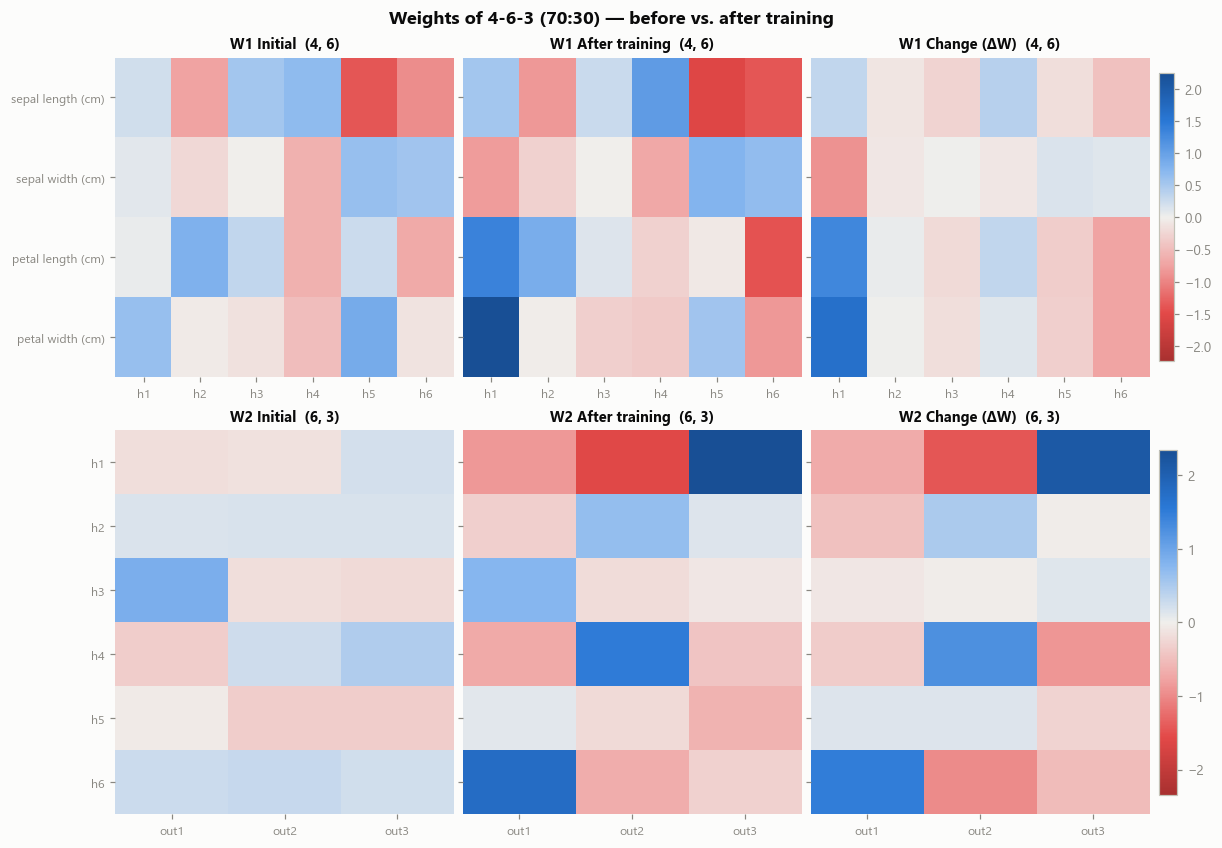

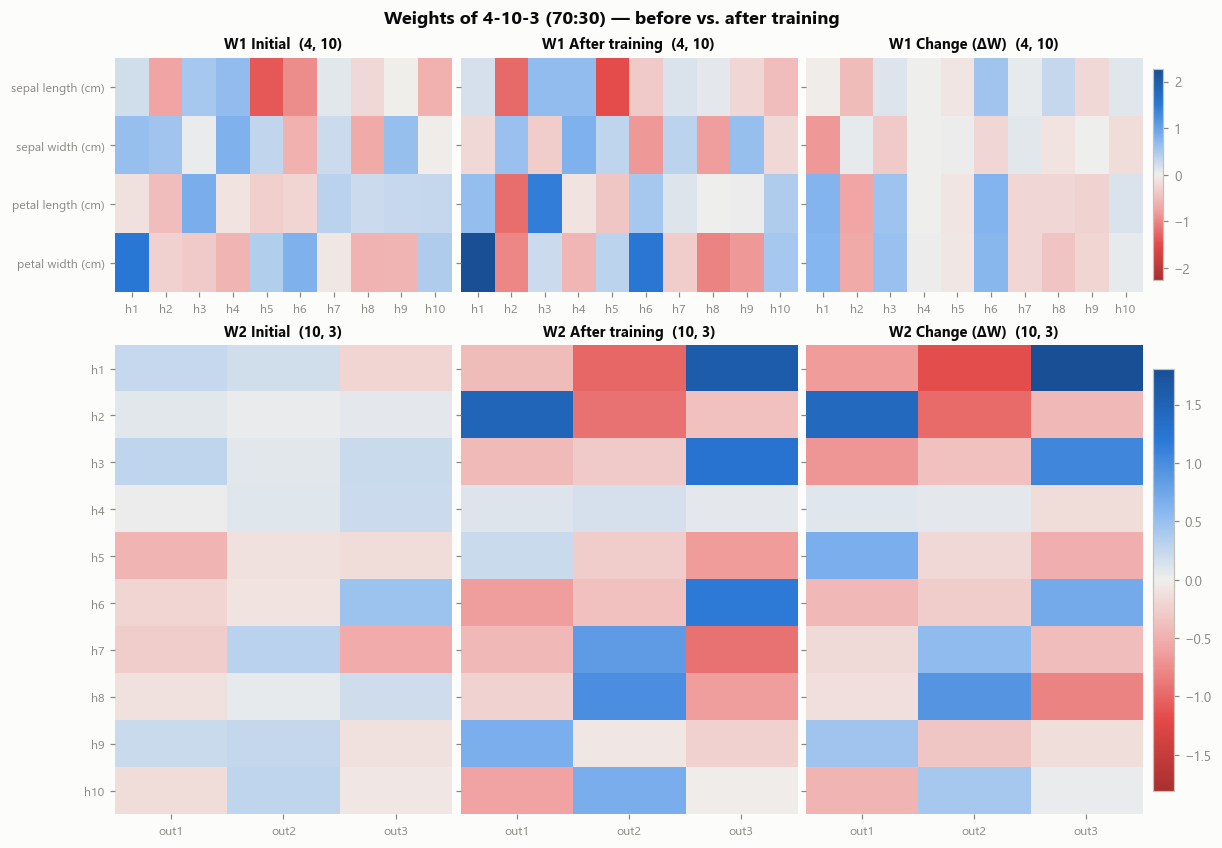

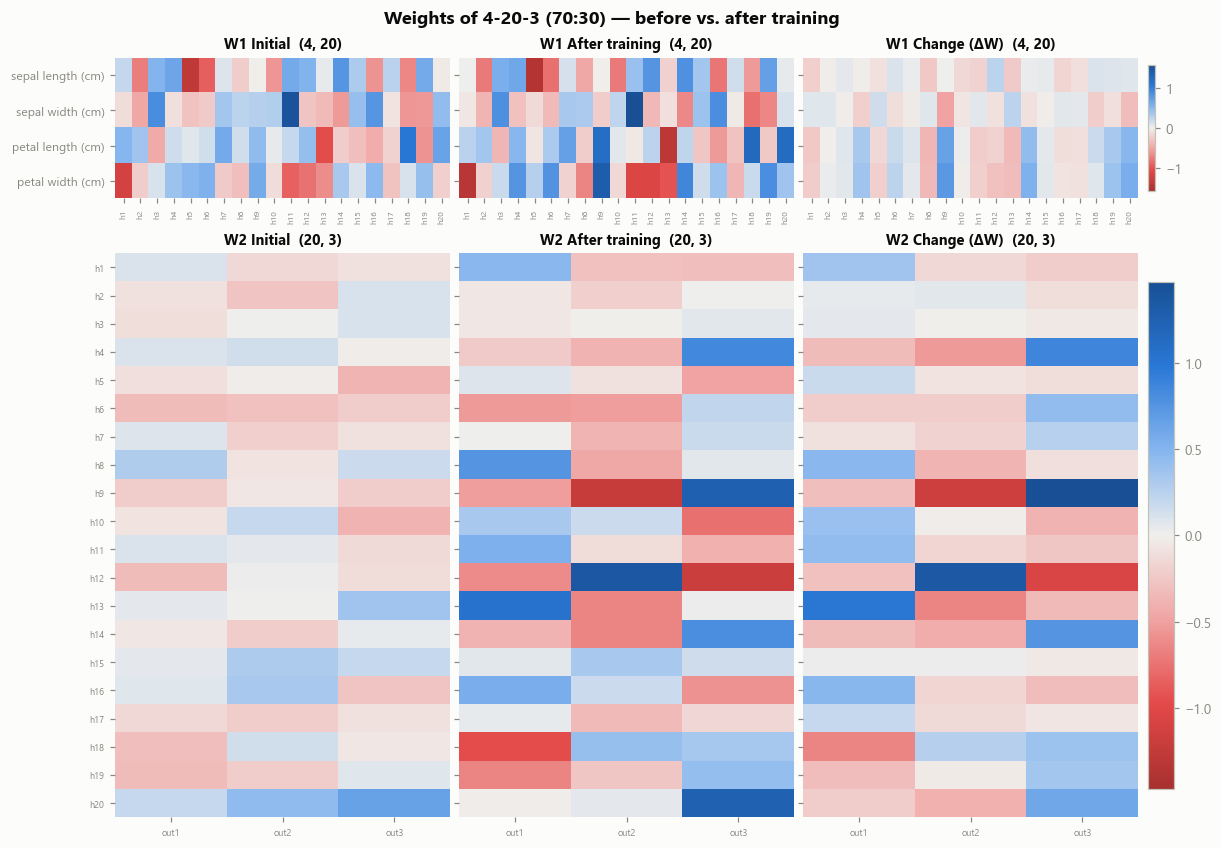

In [19]:
for r in results[:3]:      # one heatmap per architecture (70:30 split)
    H.plot_weights(r["model"], f"Weights of {r['arch']} ({r['split']}) — before vs. after training",
                   in_labels=feature_names if X.shape[1] <= 8 else short,
                   save=f"{OUT_DIR}/weights_{r['arch']}.png"); plt.show()

In [20]:
wc = H.weight_change_table(results)
wc.to_csv(f"{OUT_DIR}/weight_change.csv", index=False)
display(H.format_table(wc))

,Architecture,Split,Layer,||W_init||,||W_final||,||ΔW||,mean |ΔW|,||b_final||
0,4-6-3,70:30,"W1 (4, 6)",2.8657,4.4183,2.6740,0.3689,1.9563
1,4-6-3,70:30,"W2 (6, 3)",1.3589,4.1231,3.6941,0.6423,1.9428
2,4-10-3,70:30,"W1 (4, 10)",3.6509,4.8851,2.4938,0.2918,1.8960
3,4-10-3,70:30,"W2 (10, 3)",1.2479,3.9697,3.7521,0.5442,2.1134
4,4-20-3,70:30,"W1 (4, 20)",4.8696,5.8875,2.2460,0.1871,2.1550
5,4-20-3,70:30,"W2 (20, 3)",1.6419,4.2814,3.6861,0.3471,1.5992
6,4-6-3,80:20,"W1 (4, 6)",2.8657,4.3761,2.6395,0.3646,1.8514
7,4-6-3,80:20,"W2 (6, 3)",1.3589,4.0286,3.5970,0.6136,2.0218
8,4-10-3,80:20,"W1 (4, 10)",3.6509,4.8666,2.4928,0.2969,1.8562
9,4-10-3,80:20,"W2 (10, 3)",1.2479,3.9275,3.6793,0.5470,2.0665


## 9. Extension — deeper networks with 2–5 hidden layers (still from scratch)

The `MLP` class accepts any list of layer sizes, so the exact same NumPy code (same forward/backward
equations, applied layer by layer) is used for deeper networks. Hidden widths taper towards the output.
Hyperparameters are unchanged (lr = 0.1, 1000 epochs) so the comparison with the 1-hidden-layer
networks is fair.

In [21]:
DEEP_ARCHS = [[4, 10, 10, 3], [4, 12, 10, 8, 3], [4, 16, 12, 8, 6, 3], [4, 20, 16, 12, 8, 6, 3]]
gc = gradient_check(MLP(DEEP_ARCHS[-1], output="softmax", seed=0), X_tr[:15], y_tr[:15])
print("gradient check on the 5-hidden-layer net, max relative error:", max(e for *_, e in gc))

deep_results = []
for ts in SPLITS:
    for arch in DEEP_ARCHS:
        r = H.run_experiment(X, y, arch, "softmax", ts, lr=0.1, epochs=1000)
        deep_results.append(r)
deep_table = H.metrics_table(deep_results)
deep_table.insert(1, "Hidden layers", [len(a) - 2 for a in DEEP_ARCHS] * len(SPLITS))
deep_table.to_csv(f"{OUT_DIR}/deep_metrics_table.csv")
display(H.format_table(deep_table))

gradient check on the 5-hidden-layer net, max relative error: 3.2886696480565065e-10


,Architecture,Hidden layers,Split,Train / Test,Params,Final train loss,Train acc,Test acc,Precision,Recall,F1-score
Exp,,,,,,,,,,,
1,4-10-10-3,2,70:30,105 / 45,193,0.0182,1.0000,0.9111,0.9155,0.9111,0.9107
2,4-12-10-8-3,3,70:30,105 / 45,305,0.0065,1.0000,0.9333,0.9444,0.9333,0.9327
3,4-16-12-8-6-3,4,70:30,105 / 45,463,0.0022,1.0000,0.9111,0.9155,0.9111,0.9107
4,4-20-16-12-8-6-3,5,70:30,105 / 45,819,0.0080,1.0000,0.9333,0.9345,0.9333,0.9333
5,4-10-10-3,2,80:20,120 / 30,193,0.0360,0.9833,0.9667,0.9697,0.9667,0.9666
6,4-12-10-8-3,3,80:20,120 / 30,305,0.0078,1.0000,0.9333,0.9333,0.9333,0.9333
7,4-16-12-8-6-3,4,80:20,120 / 30,463,0.0029,1.0000,0.9667,0.9697,0.9667,0.9666
8,4-20-16-12-8-6-3,5,80:20,120 / 30,819,0.0082,1.0000,0.9333,0.9333,0.9333,0.9333


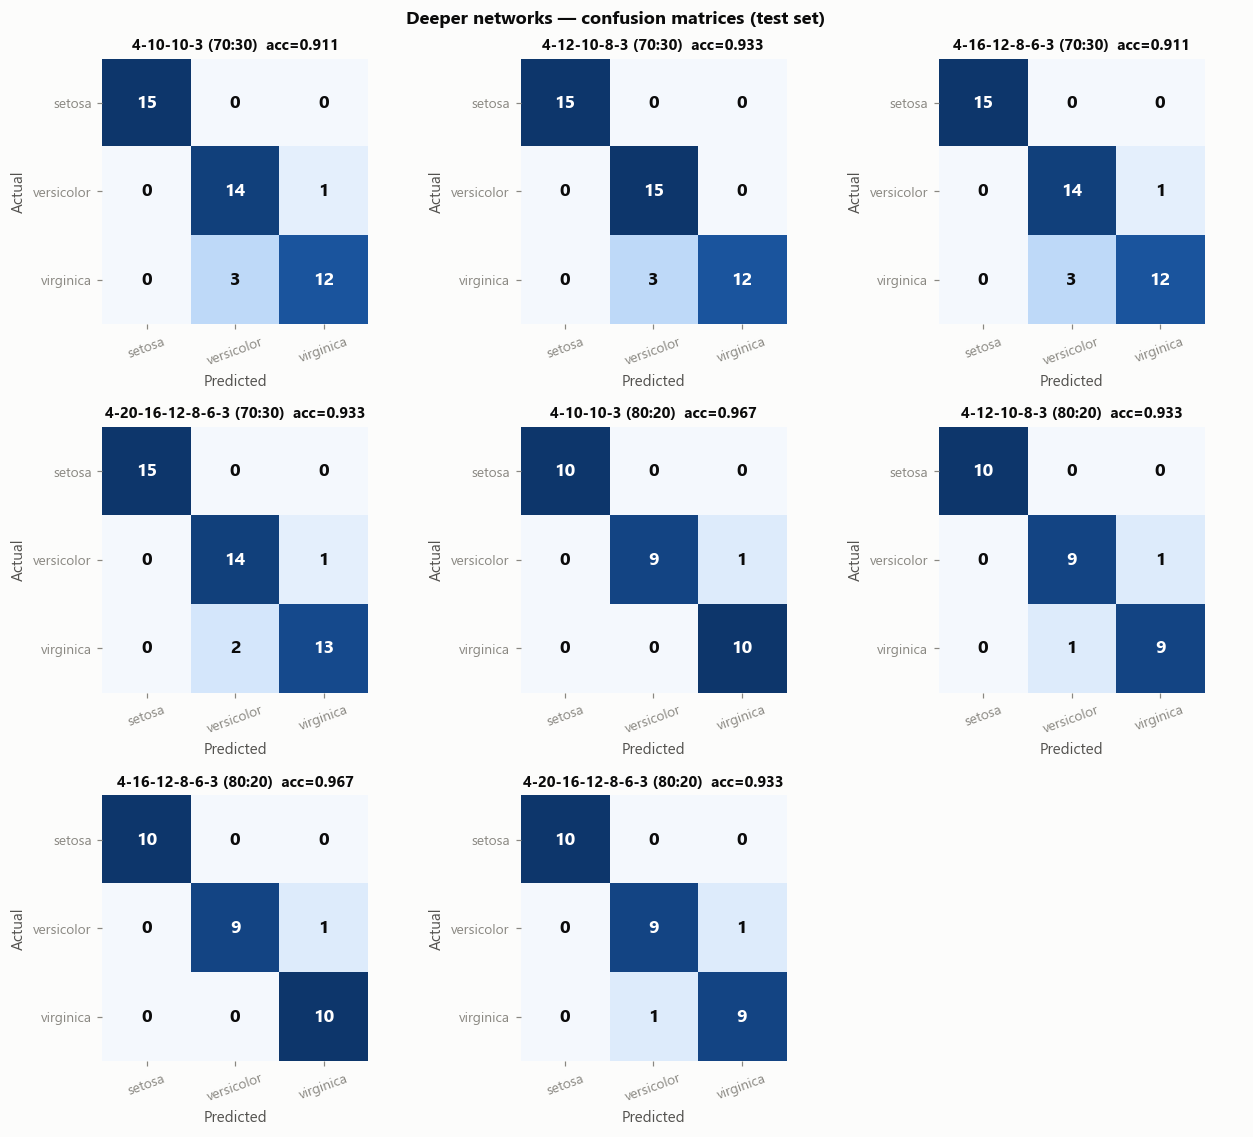

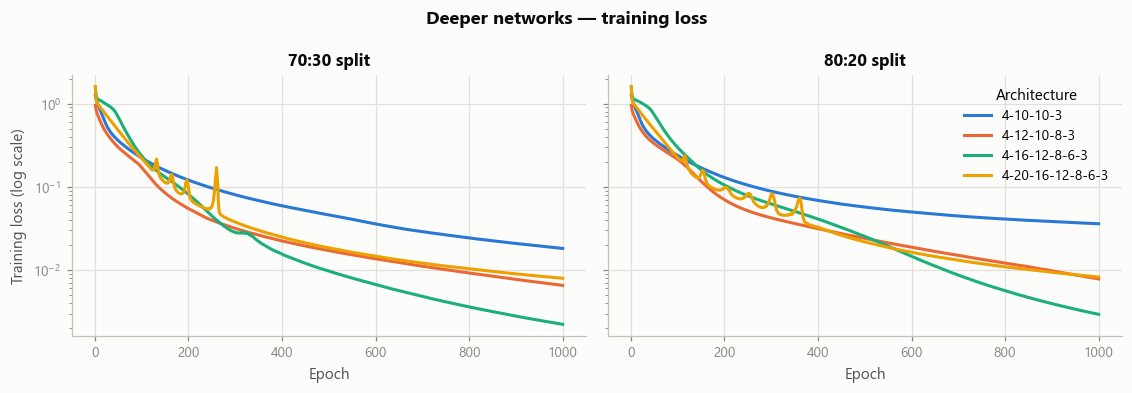

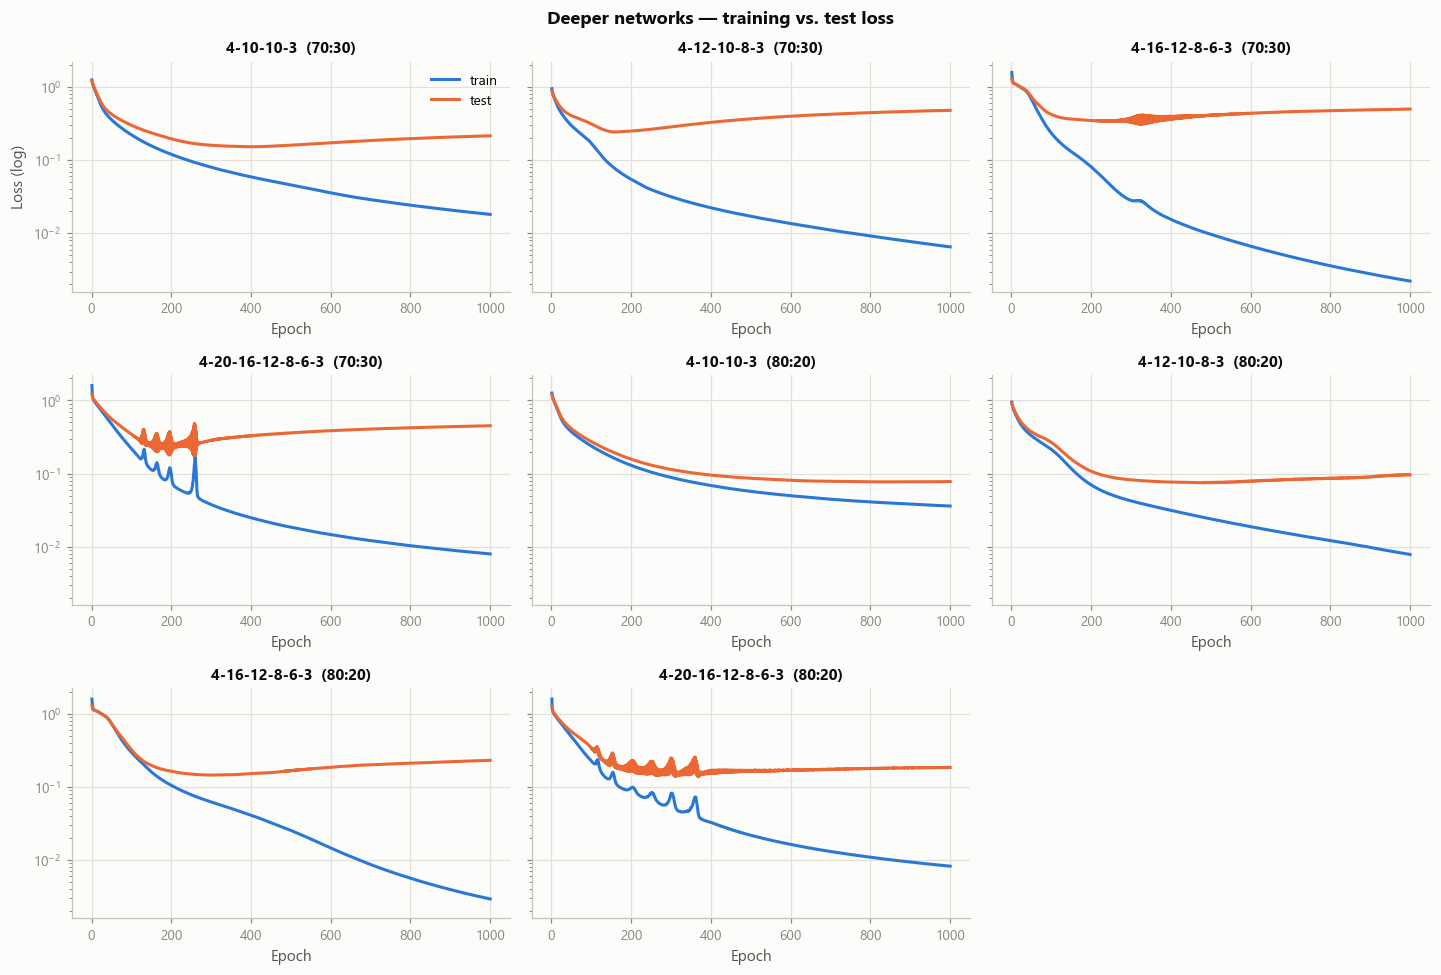

In [22]:
H.plot_confusion_matrices(deep_results, class_names, "Deeper networks — confusion matrices (test set)",
                          save=f"{OUT_DIR}/deep_confusion_matrices.png"); plt.show()
H.plot_loss_by_split(deep_results, "Deeper networks — training loss",
                     save=f"{OUT_DIR}/deep_loss_curves.png"); plt.show()
H.plot_train_test_loss(deep_results, "Deeper networks — training vs. test loss",
                       save=f"{OUT_DIR}/deep_train_vs_test_loss.png"); plt.show()

## 10. Discussion

### Summary of the six experiments (test accuracy)

| Split | 4–6–3 | 4–10–3 | 4–20–3 |
|---|---|---|---|
| 70:30 (45 test samples) | 91.11 % | 91.11 % | 91.11 % |
| 80:20 (30 test samples) | 96.67 % | 93.33 % | 96.67 % |

**The network learns.** In every experiment the training loss falls from 1.0–1.5 (near ln 3 ≈ 1.10, the
loss of a random guess among three classes) to ≈0.04. Training accuracy reaches 97.5–100 % and test
accuracy 91–97 %. The weight matrices change substantially: for 4–6–3 the norm of W2 grows from 1.36 to
4.12. The weights connecting **petal length and petal width** to the hidden layer grow the most (for
example, petal width → h1 goes from 0.62 to 2.24). That matches the scatter plot in section 1, where the
petal features separate the species.

**Where the errors are.** Setosa is classified perfectly in all experiments. Every error is a
Versicolor ↔ Virginica confusion, and those are exactly the two classes that overlap in feature space.

### Effect of hidden-layer size

* **All three sizes give practically the same result.** On the 70:30 split all three make exactly the
  same four mistakes, and their final training losses are almost identical (0.0365 / 0.0374 / 0.0350).
  With four input features and nearly separable classes, 6 hidden ReLU units already give enough capacity.
  Going to 20 units triples the number of parameters (51 → 163) but adds no information.
* On the 80:20 split, 4–6–3 and 4–20–3 make one error and 4–10–3 makes two. A difference of one flower in
  a 30-sample test set is not a meaningful difference between the architectures.
* **Wider layers spread the learning across more neurons.** The mean absolute change of each W1 weight
  falls from 0.37 (6 hidden) to 0.29 (10 hidden) to 0.19 (20 hidden).
* **Deeper networks (section 9, 2–5 hidden layers)** drive the training loss much lower (down to ≈0.002,
  100 % training accuracy) but do **not** improve test accuracy (91–97 %, the same range as one hidden
  layer). For a problem this simple, extra depth only adds parameters that can memorise the training set.

### Effect of the training-data proportion

* 80:20 gives higher test accuracy than 70:30 for all three architectures (93–97 % vs. 91 %). With more
  training examples (120 vs. 105) the networks see more of the Versicolor/Virginica boundary.
* Part of the gap comes from the different test sets. The 70:30 test set contains three Virginica flowers
  lying inside the Versicolor region, and all three networks misclassify them.
* The 80:20 test set has only 30 samples, so one error costs 3.3 % accuracy (vs. 2.2 % at 70:30). The
  80:20 accuracy figures are therefore less precise estimates.
* The train-vs-test loss curves (section 7) show that at 70:30 the test loss stops improving after
  ≈500–600 epochs and rises slightly afterwards while the training loss keeps falling. That is mild
  overfitting. At 80:20 the test loss is still going down at epoch 1000.

### Conclusion
A from-scratch MLP with a single hidden layer of only 6 ReLU neurons classifies Iris with 91–97 % test
accuracy. Larger hidden layers do not help on this small, almost linearly separable dataset. A larger
training share (80:20) gives better test accuracy. The remaining errors come from the natural overlap
between Versicolor and Virginica, not from a lack of model capacity.